# Air Quality Classification Using Random Forest

## Bayesian Hyperparameter Optimization

### Project Objective

This notebook implements a Random Forest classifier to predict air quality levels using environmental and demographic features.

Bayesian Optimization is applied to guide hyperparameter selection based on previous trial results and evaluate classification performance and computational efficiency.

### Classification Classes

- Good
- Moderate
- Poor
- Hazardous

### Optimization Technique

Bayesian Optimization using Optuna's Tree-structured Parzen Estimator (TPE) with 3-Fold Stratified Cross-Validation and Macro F1-Score.

In [1]:
import os

for folder, subfolders, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(folder, file))

/kaggle/input/datasets/mujtabamatin/air-quality-and-pollution-assessment/updated_pollution_dataset.csv


In [2]:
import os
import time
import platform

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from pathlib import Path
from types import SimpleNamespace

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_validate
)

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    log_loss
)

RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 3
SCORING = 'f1_macro'
N_JOBS = -1

OUTPUT_DIR = Path('/kaggle/working')

print("Python Version:", platform.python_version())
print("Scikit-learn Version:", sklearn.__version__)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Optuna Version:", optuna.__version__)
print("CPU Cores:", os.cpu_count())

Python Version: 3.13.18
Scikit-learn Version: 1.6.1
Pandas Version: 2.3.3
NumPy Version: 2.1.3
Optuna Version: 5.1.0
CPU Cores: 4


In [3]:
data_path = next(
    Path('/kaggle/input').rglob('updated_pollution_dataset.csv')
)

df = pd.read_csv(data_path)

df.head()

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (5000, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Temperature                    5000 non-null   float64
 1   Humidity                       5000 non-null   float64
 2   PM2.5                          5000 non-null   float64
 3   PM10                           5000 non-null   float64
 4   NO2                            5000 non-null   float64
 5   SO2                            5000 non-null   float64
 6   CO                             5000 non-null   float64
 7   Proximity_to_Industrial_Areas  5000 non-null   float64
 8   Population_Density             5000 non-null   int64  
 9   Air Quality                    5000 non-null   object 
dtypes: float64(8), int64(1), object(1)
memory usage: 390.8+ KB

Missing Values:
Temperature                      0
Humidity 

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,30.029020,70.056120,20.142140,30.218360,26.412100,10.014820,1.500354,8.425400,497.423800
std,6.720661,15.863577,24.554546,27.349199,8.895356,6.750303,0.546027,3.610944,152.754084
min,13.400000,36.000000,0.000000,-0.200000,7.400000,-6.200000,0.650000,2.500000,188.000000
25%,25.100000,58.300000,4.600000,12.300000,20.100000,5.100000,1.030000,5.400000,381.000000
50%,29.000000,69.800000,12.000000,21.700000,25.300000,8.000000,1.410000,7.900000,494.000000
75%,34.000000,80.300000,26.100000,38.100000,31.900000,13.725000,1.840000,11.100000,600.000000
max,58.600000,128.100000,295.000000,315.800000,64.900000,44.900000,3.720000,25.800000,957.000000


In [5]:
df.columns = df.columns.str.strip()

df['Air Quality'] = df['Air Quality'].str.strip()

rows_before = len(df)

df = df.drop_duplicates().dropna().reset_index(drop=True)

print("Rows Removed:", rows_before - len(df))
print("Dataset Shape After Cleaning:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Values:", df.duplicated().sum())

range_checks = pd.Series({
    "Humidity > 100%": (df['Humidity'] > 100).sum(),
    "Humidity < 0%": (df['Humidity'] < 0).sum(),
    "Negative PM2.5": (df['PM2.5'] < 0).sum(),
    "Negative PM10": (df['PM10'] < 0).sum(),
    "Negative SO2": (df['SO2'] < 0).sum(),
    "Negative NO2": (df['NO2'] < 0).sum(),
    "Negative CO": (df['CO'] < 0).sum(),
    "PM2.5 > PM10": (df['PM2.5'] > df['PM10']).sum()
}, name="Number of Records")

print("\nPhysical Plausibility Check:")

display(range_checks.to_frame())

Rows Removed: 0
Dataset Shape After Cleaning: (5000, 10)
Missing Values: 0
Duplicate Values: 0

Physical Plausibility Check:


,Number of Records
Humidity > 100%,195
Humidity < 0%,0
Negative PM2.5,0
Negative PM10,1
Negative SO2,30
Negative NO2,0
Negative CO,0
PM2.5 > PM10,32


In [6]:
print("Number of Classes:", df['Air Quality'].nunique())

print("\nClass Distribution:")
print(df['Air Quality'].value_counts())

print("\nClass Percentage:")
print(df['Air Quality'].value_counts(normalize=True) * 100)

Number of Classes: 4

Class Distribution:
Air Quality
Good         2000
Moderate     1500
Poor         1000
Hazardous     500
Name: count, dtype: int64

Class Percentage:
Air Quality
Good         40.0
Moderate     30.0
Poor         20.0
Hazardous    10.0
Name: proportion, dtype: float64


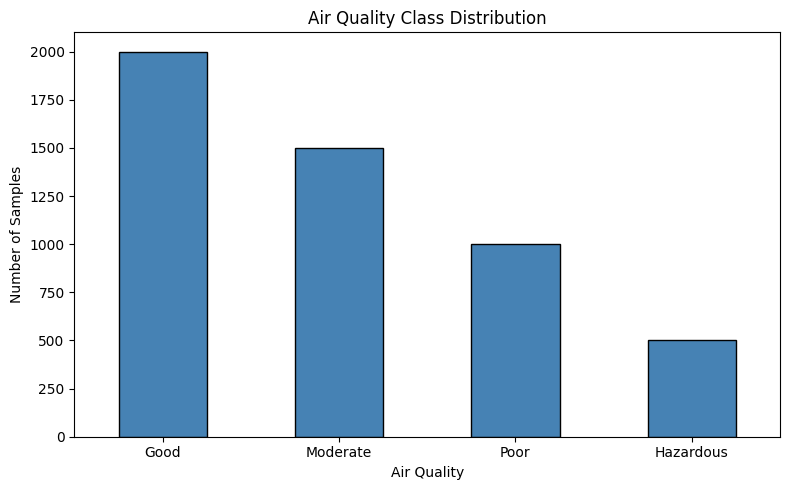

In [7]:
plt.figure(figsize=(8, 5))

df['Air Quality'].value_counts().plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title("Air Quality Class Distribution")
plt.xlabel("Air Quality")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

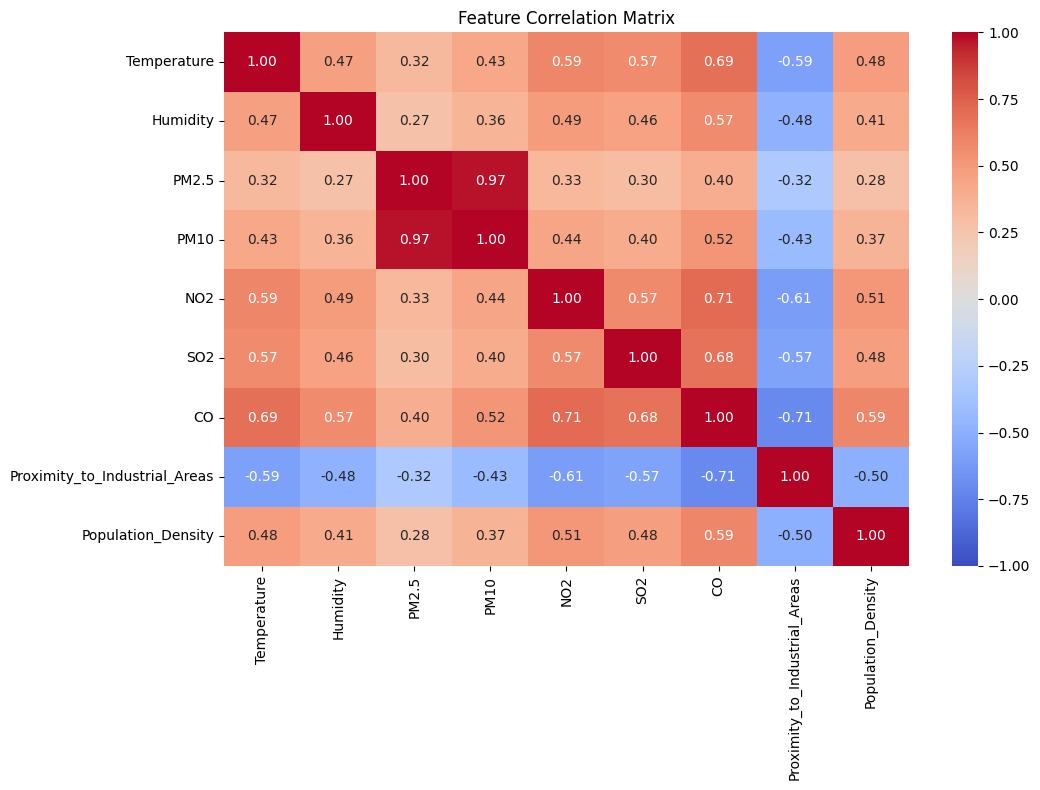

In [8]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [9]:
X = df.drop('Air Quality', axis=1)

y = df['Air Quality']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features Shape: (5000, 9)
Target Shape: (5000,)

Features:
['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Proximity_to_Industrial_Areas', 'Population_Density']


In [10]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

for index, label in enumerate(class_names):
    print(f"{label}: {index}")

Good: 0
Hazardous: 1
Moderate: 2
Poor: 3


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

split_check = pd.DataFrame({
    "Full Data (%)": pd.Series(y).value_counts(
        normalize=True
    ).sort_index() * 100,

    "Train (%)": pd.Series(y_train).value_counts(
        normalize=True
    ).sort_index() * 100,

    "Test (%)": pd.Series(y_test).value_counts(
        normalize=True
    ).sort_index() * 100
})

split_check.index = class_names

display(split_check.round(2))

Training Samples: 4000
Testing Samples: 1000


,Full Data (%),Train (%),Test (%)
Good,40.0,40.0,40.0
Hazardous,10.0,10.0,10.0
Moderate,30.0,30.0,30.0
Poor,20.0,20.0,20.0


In [12]:
baseline_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    oob_score=True,
    n_jobs=-1
)

start_time = time.time()

baseline_model.fit(X_train, y_train)

baseline_training_time = time.time() - start_time

baseline_predictions = baseline_model.predict(X_test)
baseline_proba = baseline_model.predict_proba(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

baseline_precision = precision_score(
    y_test,
    baseline_predictions,
    average='macro',
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    baseline_predictions,
    average='macro',
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    average='macro'
)

baseline_roc_auc = roc_auc_score(
    y_test,
    baseline_proba,
    multi_class='ovr',
    average='macro'
)

baseline_log_loss = log_loss(
    y_test,
    baseline_proba
)

baseline_oob_score = baseline_model.oob_score_
baseline_oob_error = 1 - baseline_oob_score

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Precision:", baseline_precision)
print("Baseline Recall:", baseline_recall)
print("Baseline F1-Score:", baseline_f1)
print("Baseline ROC-AUC:", baseline_roc_auc)
print("Baseline Log Loss:", baseline_log_loss)
print("Baseline OOB Score:", baseline_oob_score)
print("Baseline OOB Error:", baseline_oob_error)
print("Training Time:", baseline_training_time)

Baseline Accuracy: 0.951
Baseline Precision: 0.93133585330834
Baseline Recall: 0.9175
Baseline F1-Score: 0.9236106892311261
Baseline ROC-AUC: 0.9933605034722222
Baseline Log Loss: 0.17180715810486594
Baseline OOB Score: 0.958
Baseline OOB Error: 0.04200000000000004
Training Time: 0.6011044979095459


In [13]:
OPTIMIZER_NAME = "Bayesian Optimization"

param_grid = {
    'n_estimators': [100, 200],
    'max_features': ['sqrt', None],
    'max_depth': [10, None],
    'max_leaf_nodes': [50, None],
    'max_samples': [0.8, None],
    'min_samples_split': [2, 5],
    'criterion': ['gini', 'entropy']
}

N_TRIALS = 32
N_STARTUP_TRIALS = 8

default_params = RandomForestClassifier().get_params()

BASELINE_PARAMS = {
    name: default_params[name]
    for name in param_grid
}

search_space_size = int(np.prod([
    len(values) for values in param_grid.values()
]))

total_combinations = N_TRIALS

TOTAL_CV_FITS = N_TRIALS * CV_FOLDS

print("Optimizer:", OPTIMIZER_NAME)
print("Baseline Parameters:", BASELINE_PARAMS)
print("Search Space Size:", search_space_size)
print("Number of Trials:", N_TRIALS)
print("Startup Trials:", N_STARTUP_TRIALS)
print("Cross-Validation Folds:", CV_FOLDS)
print("Total CV Fits:", TOTAL_CV_FITS)

Optimizer: Bayesian Optimization
Baseline Parameters: {'n_estimators': 100, 'max_features': 'sqrt', 'max_depth': None, 'max_leaf_nodes': None, 'max_samples': None, 'min_samples_split': 2, 'criterion': 'gini'}
Search Space Size: 128
Number of Trials: 32
Startup Trials: 8
Cross-Validation Folds: 3
Total CV Fits: 96


In [14]:
model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=1
)

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

start_time = time.time()

baseline_cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=SCORING,
    n_jobs=1
)

baseline_cv_time = time.time() - start_time

baseline_cv_f1 = baseline_cv_scores.mean()
baseline_cv_std = baseline_cv_scores.std()

print("Baseline CV Scores:", baseline_cv_scores)
print("Baseline CV F1-Score:", baseline_cv_f1)
print("Baseline CV F1 Std:", baseline_cv_std)
print("Baseline CV Time:", baseline_cv_time)


def objective(trial):

    params = {
        name: trial.suggest_categorical(name, values)
        for name, values in param_grid.items()
    }

    trial_model = RandomForestClassifier(
        **params,
        random_state=RANDOM_STATE,
        n_jobs=1
    )

    cv_scores = cross_validate(
        trial_model,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=N_JOBS,
        return_train_score=True,
        error_score='raise'
    )

    mean_train_score = cv_scores['train_score'].mean()

    mean_test_score = cv_scores['test_score'].mean()

    std_test_score = cv_scores['test_score'].std()

    trial.set_user_attr(
        "mean_train_score",
        float(mean_train_score)
    )

    trial.set_user_attr(
        "std_test_score",
        float(std_test_score)
    )

    return float(mean_test_score)


sampler = optuna.samplers.TPESampler(
    seed=RANDOM_STATE,
    n_startup_trials=N_STARTUP_TRIALS
)

study = optuna.create_study(
    direction='maximize',
    sampler=sampler
)

Baseline CV Scores: [0.94024457 0.92268521 0.93025788]
Baseline CV F1-Score: 0.9310625544543821
Baseline CV F1 Std: 0.007191125315406145
Baseline CV Time: 2.155428171157837


In [15]:
start_time = time.time()

study.optimize(
    objective,
    n_trials=N_TRIALS,
    n_jobs=1,
    show_progress_bar=True
)

optimization_time = time.time() - start_time

completed_trials = [
    trial for trial in study.trials
    if trial.state == optuna.trial.TrialState.COMPLETE
]

trial_results = []

for trial in completed_trials:

    row = {
        "trial_number": trial.number,
        "params": trial.params,
        "mean_train_score": trial.user_attrs[
            "mean_train_score"
        ],
        "mean_test_score": trial.value,
        "std_test_score": trial.user_attrs[
            "std_test_score"
        ]
    }

    for name, value in trial.params.items():
        row[f"param_{name}"] = value

    trial_results.append(row)

search_results = pd.DataFrame(trial_results)

search_results['rank_test_score'] = (
    search_results['mean_test_score']
    .rank(method='min', ascending=False)
    .astype(int)
)

best_index = search_results.index[
    search_results['trial_number'] == study.best_trial.number
][0]

optimizer = SimpleNamespace(
    best_params_=study.best_params,
    best_score_=study.best_value,
    best_index_=int(best_index),
    cv_results_=search_results.to_dict(orient='list')
)

total_combinations = len(completed_trials)

unique_configurations = len({
    tuple(sorted(trial.params.items()))
    for trial in completed_trials
})

TOTAL_CV_FITS = total_combinations * CV_FOLDS

print("Optimization Completed")

print("\nBest Parameters:")
print(optimizer.best_params_)

print("\nBest CV Score:", optimizer.best_score_)

print("\nCompleted Trials:", total_combinations)

print("Unique Configurations:", unique_configurations)

print("Total CV Fits:", TOTAL_CV_FITS)

print("\nOptimization Time:", optimization_time)

  0%|          | 0/32 [00:00<?, ?it/s]

Optimization Completed

Best Parameters:
{'n_estimators': 100, 'max_features': 'sqrt', 'max_depth': 10, 'max_leaf_nodes': None, 'max_samples': 0.8, 'min_samples_split': 2, 'criterion': 'gini'}

Best CV Score: 0.9336955614017604

Completed Trials: 32
Unique Configurations: 22
Total CV Fits: 96

Optimization Time: 54.38948321342468


In [16]:
cv_results = pd.DataFrame(optimizer.cv_results_)

cv_results = cv_results.sort_values(
    by='rank_test_score'
)

param_columns = [
    f"param_{name}" for name in param_grid
]

display(
    cv_results[
        ['trial_number'] + param_columns + [
            'mean_train_score',
            'mean_test_score',
            'std_test_score',
            'rank_test_score'
        ]
    ].head(10)
)

print("Baseline CV F1:", round(baseline_cv_f1, 6))

print("Best Bayesian CV F1:",
      round(optimizer.best_score_, 6))

print("CV F1 Improvement:",
      round(optimizer.best_score_ - baseline_cv_f1, 6))

print("Completed Trials:", total_combinations)

print("Unique Configurations:", unique_configurations)

print("Repeated Configurations:",
      total_combinations - unique_configurations)

print("Best Trial Number:", study.best_trial.number)

,trial_number,param_n_estimators,param_max_features,param_max_depth,param_max_leaf_nodes,param_max_samples,param_min_samples_split,param_criterion,mean_train_score,mean_test_score,std_test_score,rank_test_score
27,27,100,sqrt,10.0,NaN,0.8,2,gini,0.984925,0.933696,0.013823,1
31,31,100,sqrt,10.0,NaN,0.8,2,gini,0.984925,0.933696,0.013823,1
30,30,100,sqrt,10.0,NaN,0.8,2,gini,0.984925,0.933696,0.013823,1
29,29,100,sqrt,10.0,NaN,0.8,2,gini,0.984925,0.933696,0.013823,1
15,15,100,sqrt,10.0,NaN,0.8,5,gini,0.979560,0.933224,0.009149,5
21,21,100,sqrt,10.0,NaN,0.8,5,gini,0.979560,0.933224,0.009149,5
17,17,100,sqrt,10.0,NaN,0.8,5,gini,0.979560,0.933224,0.009149,5
16,16,100,sqrt,10.0,NaN,0.8,5,gini,0.979560,0.933224,0.009149,5
9,9,100,sqrt,10.0,NaN,NaN,5,entropy,0.988986,0.931066,0.004908,9
10,10,100,sqrt,10.0,NaN,NaN,5,entropy,0.988986,0.931066,0.004908,9


Baseline CV F1: 0.931063
Best Bayesian CV F1: 0.933696
CV F1 Improvement: 0.002633
Completed Trials: 32
Unique Configurations: 22
Repeated Configurations: 10
Best Trial Number: 27


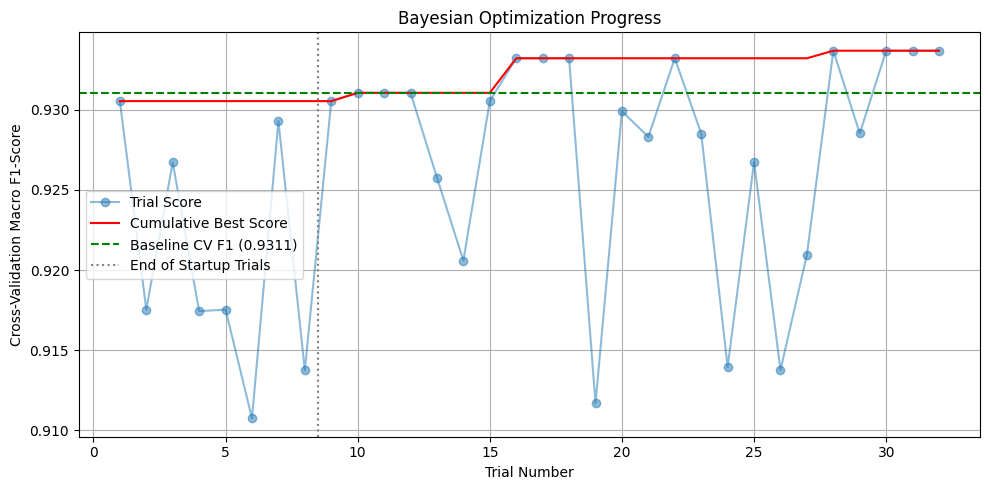

In [17]:
scores = np.array(
    optimizer.cv_results_['mean_test_score']
)

best_scores = np.maximum.accumulate(scores)

trial_numbers = np.arange(1, len(scores) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    trial_numbers,
    scores,
    label='Trial Score',
    alpha=0.5,
    marker='o'
)

plt.plot(
    trial_numbers,
    best_scores,
    label='Cumulative Best Score',
    color='red'
)

plt.axhline(
    baseline_cv_f1,
    color='green',
    linestyle='--',
    label=f'Baseline CV F1 ({baseline_cv_f1:.4f})'
)

plt.axvline(
    N_STARTUP_TRIALS + 0.5,
    color='gray',
    linestyle=':',
    label='End of Startup Trials'
)

plt.title("Bayesian Optimization Progress")
plt.xlabel("Trial Number")
plt.ylabel("Cross-Validation Macro F1-Score")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
best_model = RandomForestClassifier(
    **optimizer.best_params_,
    random_state=RANDOM_STATE,
    oob_score=True,
    n_jobs=-1
)

print(best_model)

RandomForestClassifier(max_depth=10, max_samples=0.8, n_jobs=-1, oob_score=True,
                       random_state=42)


In [19]:
start_time = time.time()

best_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Model Training Completed")

print("Number of Trees:", len(best_model.estimators_))

print("Training Time:", training_time)

Model Training Completed
Number of Trees: 100
Training Time: 0.5186619758605957


In [20]:
y_train_pred = best_model.predict(X_train)

y_pred = best_model.predict(X_test)

y_pred_proba = best_model.predict_proba(X_test)

print("Predictions Shape:", y_pred.shape)

print("Probabilities Shape:", y_pred_proba.shape)

Predictions Shape: (1000,)
Probabilities Shape: (1000, 4)


In [21]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average='macro',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

roc_auc = roc_auc_score(
    y_test,
    y_pred_proba,
    multi_class='ovr',
    average='macro'
)

test_log_loss = log_loss(
    y_test,
    y_pred_proba
)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("Log Loss:", round(test_log_loss, 4))

Accuracy: 0.95
Precision: 0.9321
Recall: 0.9163
F1-Score: 0.9232
ROC-AUC: 0.9934
Log Loss: 0.1488


In [22]:
oob_score = best_model.oob_score_

oob_error = 1 - oob_score

print("OOB Score:", round(oob_score, 4))

print("OOB Error:", round(oob_error, 4))

OOB Score: 0.953
OOB Error: 0.047


In [23]:
baseline_train_pred = baseline_model.predict(X_train)

baseline_train_accuracy = accuracy_score(
    y_train,
    baseline_train_pred
)

baseline_train_f1 = f1_score(
    y_train,
    baseline_train_pred,
    average='macro'
)

train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

train_f1 = f1_score(
    y_train,
    y_train_pred,
    average='macro'
)

baseline_accuracy_gap = (
    baseline_train_accuracy - baseline_accuracy
)

baseline_f1_gap = baseline_train_f1 - baseline_f1

accuracy_gap = train_accuracy - accuracy

f1_gap = train_f1 - f1

best_idx = optimizer.best_index_

cv_train_f1 = optimizer.cv_results_[
    'mean_train_score'
][best_idx]

cv_val_f1 = optimizer.best_score_

cv_f1_gap = cv_train_f1 - cv_val_f1

overfitting_summary = pd.DataFrame({
    "Model": [
        "Baseline Random Forest",
        "Optimized Random Forest"
    ],
    "Training Accuracy": [
        baseline_train_accuracy,
        train_accuracy
    ],
    "Testing Accuracy": [
        baseline_accuracy,
        accuracy
    ],
    "Training F1": [
        baseline_train_f1,
        train_f1
    ],
    "Testing F1": [
        baseline_f1,
        f1
    ],
    "Accuracy Gap": [
        baseline_accuracy_gap,
        accuracy_gap
    ],
    "F1 Gap": [
        baseline_f1_gap,
        f1_gap
    ],
    "OOB Accuracy": [
        baseline_oob_score,
        oob_score
    ],
    "OOB-Test Accuracy Gap": [
        baseline_oob_score - baseline_accuracy,
        oob_score - accuracy
    ]
})

display(overfitting_summary.round(4).T)

print("Mean CV Training F1:", round(cv_train_f1, 4))
print("Mean CV Validation F1:", round(cv_val_f1, 4))
print("CV F1 Gap:", round(cv_f1_gap, 4))

,0,1
Model,Baseline Random Forest,Optimized Random Forest
Training Accuracy,1.0,0.984
Testing Accuracy,0.951,0.95
Training F1,1.0,0.9775
Testing F1,0.9236,0.9232
Accuracy Gap,0.049,0.034
F1 Gap,0.0764,0.0542
OOB Accuracy,0.958,0.953
OOB-Test Accuracy Gap,0.007,0.003


Mean CV Training F1: 0.9849
Mean CV Validation F1: 0.9337
CV F1 Gap: 0.0512


In [24]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Good       1.00      1.00      1.00       400
   Hazardous       0.91      0.80      0.85       100
    Moderate       0.96      0.97      0.96       300
        Poor       0.86      0.90      0.88       200

    accuracy                           0.95      1000
   macro avg       0.93      0.92      0.92      1000
weighted avg       0.95      0.95      0.95      1000



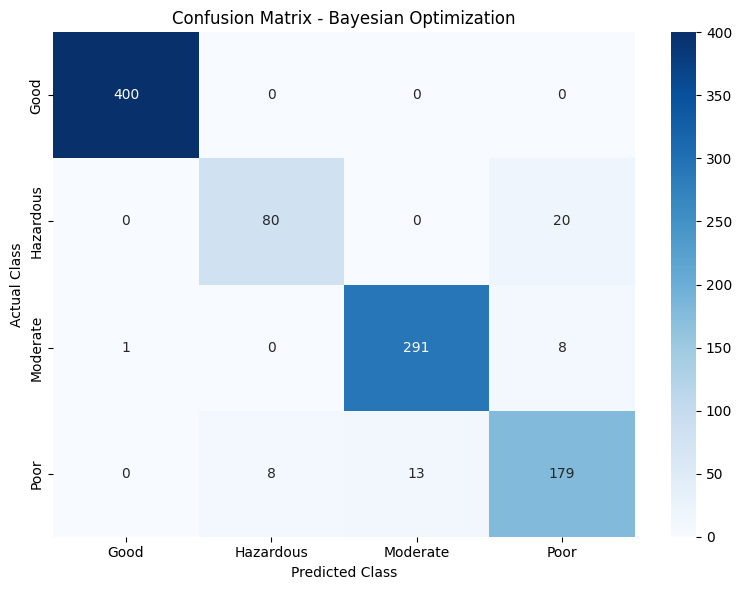

In [25]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Bayesian Optimization")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

,Feature,Importance
6,CO,0.355717
7,Proximity_to_Industrial_Areas,0.295867
4,NO2,0.091791
5,SO2,0.087629
0,Temperature,0.069832
8,Population_Density,0.036332
1,Humidity,0.034693
3,PM10,0.019039
2,PM2.5,0.009100


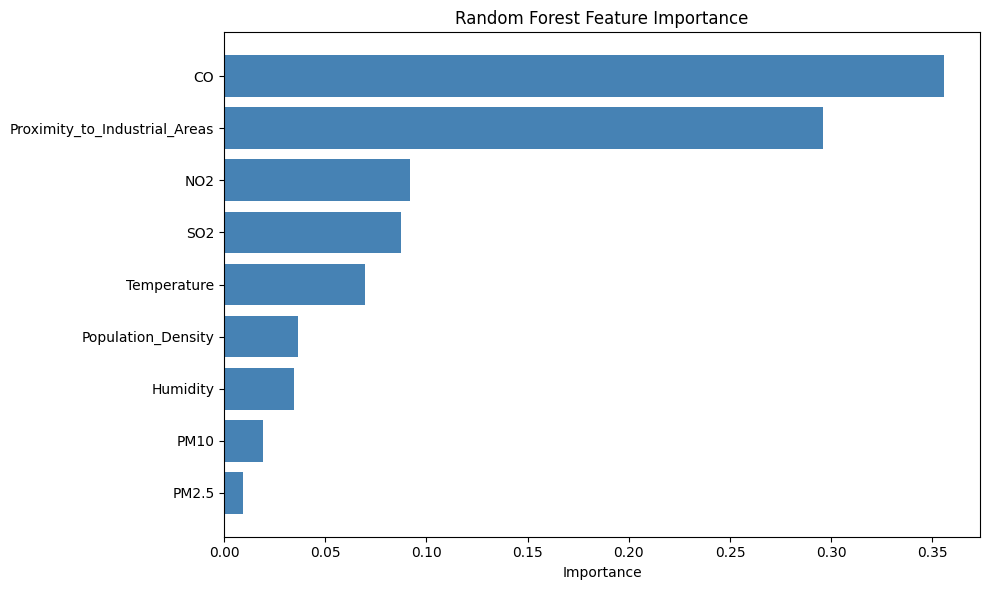

In [26]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance'],
    color='steelblue'
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [27]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline Random Forest",
        "Optimized Random Forest"
    ],
    "CV F1-Score": [
        baseline_cv_f1,
        optimizer.best_score_
    ],
    "CV F1 Std": [
        baseline_cv_std,
        optimizer.cv_results_[
            'std_test_score'
        ][optimizer.best_index_]
    ],
    "Accuracy": [
        baseline_accuracy,
        accuracy
    ],
    "Correct Test Predictions": [
        int((baseline_predictions == y_test).sum()),
        int((y_pred == y_test).sum())
    ],
    "Precision": [
        baseline_precision,
        precision
    ],
    "Recall": [
        baseline_recall,
        recall
    ],
    "F1-Score": [
        baseline_f1,
        f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        roc_auc
    ],
    "Log Loss": [
        baseline_log_loss,
        test_log_loss
    ],
    "OOB Score": [
        baseline_oob_score,
        oob_score
    ],
    "OOB Error": [
        baseline_oob_error,
        oob_error
    ],
    "Training Accuracy": [
        baseline_train_accuracy,
        train_accuracy
    ],
    "Accuracy Gap": [
        baseline_accuracy_gap,
        accuracy_gap
    ],
    "Training Time": [
        baseline_training_time,
        training_time
    ],
    "Optimization Time": [
        0,
        optimization_time
    ],
    "Total Time": [
        baseline_training_time,
        training_time + optimization_time
    ]
})

display(
    comparison.set_index("Model").round(4).T
)

Model,Baseline Random Forest,Optimized Random Forest
CV F1-Score,0.9311,0.9337
CV F1 Std,0.0072,0.0138
Accuracy,0.9510,0.9500
Correct Test Predictions,951.0000,950.0000
Precision,0.9313,0.9321
Recall,0.9175,0.9162
F1-Score,0.9236,0.9232
ROC-AUC,0.9934,0.9934
Log Loss,0.1718,0.1488
OOB Score,0.9580,0.9530


,Baseline Random Forest,Optimized Random Forest
Good,0.9988,0.9988
Moderate,0.9668,0.9636
Poor,0.8824,0.8796
Hazardous,0.8466,0.8511


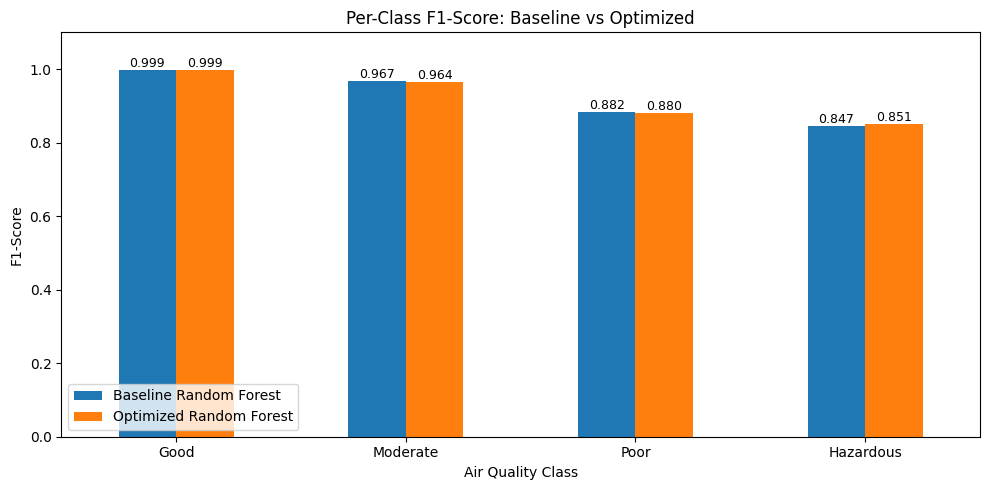

In [28]:
per_class_f1 = pd.DataFrame({
    "Baseline Random Forest": f1_score(
        y_test,
        baseline_predictions,
        average=None,
        zero_division=0
    ),
    "Optimized Random Forest": f1_score(
        y_test,
        y_pred,
        average=None,
        zero_division=0
    )
}, index=class_names)

per_class_f1 = per_class_f1.reindex([
    'Good',
    'Moderate',
    'Poor',
    'Hazardous'
])

display(per_class_f1.round(4))

ax = per_class_f1.plot(
    kind='bar',
    figsize=(10, 5),
    rot=0
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.3f',
        fontsize=9
    )

plt.title("Per-Class F1-Score: Baseline vs Optimized")
plt.xlabel("Air Quality Class")
plt.ylabel("F1-Score")
plt.ylim(0, 1.1)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [29]:
results = pd.DataFrame([{
    "Optimizer": OPTIMIZER_NAME,

    "Number of Trees": best_model.n_estimators,
    "Max Depth": best_model.max_depth,
    "Max Features": best_model.max_features,
    "Max Leaf Nodes": best_model.max_leaf_nodes,
    "Max Samples": best_model.max_samples,
    "Min Samples Split": best_model.min_samples_split,
    "Criterion": best_model.criterion,

    "Configurations Evaluated": total_combinations,
    "Total CV Fits": TOTAL_CV_FITS,
    "CV Folds": CV_FOLDS,

    "Baseline CV F1": baseline_cv_f1,
    "Best CV F1": optimizer.best_score_,

    "Best CV F1 Std": optimizer.cv_results_[
        'std_test_score'
    ][optimizer.best_index_],

    "CV F1 Improvement": (
        optimizer.best_score_ - baseline_cv_f1
    ),

    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "ROC-AUC": roc_auc,
    "Log Loss": test_log_loss,

    "Correct Test Predictions": int(
        (y_pred == y_test).sum()
    ),

    "OOB Score": oob_score,
    "OOB Error": oob_error,

    "Training Accuracy": train_accuracy,
    "Training F1": train_f1,
    "Accuracy Gap": accuracy_gap,
    "F1 Gap": f1_gap,
    "CV F1 Gap": cv_f1_gap,

    "Baseline CV Time": baseline_cv_time,
    "Training Time": training_time,
    "Optimization Time": optimization_time,

    "Total Time": (
        training_time + optimization_time
    ),

    "Random State": RANDOM_STATE,
    "Test Size": TEST_SIZE,
    "Scoring": SCORING,
    "CPU Cores": os.cpu_count(),
    "Python Version": platform.python_version(),
    "Sklearn Version": sklearn.__version__,
    "Pandas Version": pd.__version__,
    "NumPy Version": np.__version__
}])
results["Unique Configurations"] = unique_configurations
results["Optuna Version"] = optuna.__version__
display(results.round(4).T)

,0
Optimizer,Bayesian Optimization
Number of Trees,100
Max Depth,10
Max Features,sqrt
Max Leaf Nodes,None
Max Samples,0.8
Min Samples Split,2
Criterion,gini
Configurations Evaluated,32
Total CV Fits,96


In [30]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results.to_csv(
    OUTPUT_DIR / 'bayesian_optimization_results.csv',
    index=False
)

cv_results.to_csv(
    OUTPUT_DIR / 'bayesian_optimization_cv_results.csv',
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / 'bayesian_optimization_comparison.csv',
    index=False
)

overfitting_summary.to_csv(
    OUTPUT_DIR / 'bayesian_optimization_overfitting.csv',
    index=False
)

per_class_f1.to_csv(
    OUTPUT_DIR / 'bayesian_optimization_per_class_f1.csv'
)

print("Results Saved Successfully")
print("Output Directory:", OUTPUT_DIR)

Results Saved Successfully
Output Directory: /kaggle/working


## Conclusion

Bayesian Optimization improved the cross-validation
Macro F1-Score from 93.11% to 93.37%.

The test accuracy decreased slightly from 95.10% to 95.00%,
while the test Macro F1-Score decreased from 92.36% to 92.32%.

Bayesian Optimization achieved the lowest Log Loss of 0.1488
among the three optimization techniques.

The optimization required 51.66 seconds, reducing
optimization time by approximately 77.56% compared
to Grid Search.

A total of 32 trials were completed, including
22 unique hyperparameter configurations.